<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/04.Models%20with%20Distance%20Metrics%20and%20Nearest%20Neighbors/Chapter_04_Distance_Metrics_KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 4: Building Models with Distance Metrics and Nearest Neighbors

Humans easily judge whether things are similar. A child can tell that a Toyota and a cheetah are not alike, even though both can move fast; and a cheetah and a puma obviously share many characteristics. If we show the child a photo of a Toyota and ask "car or cat?", they will answer "car" because it is *more similar to the cars* they have already seen. This comparison of a new object with known objects is the basis of one of the simplest and most intuitive classification methods in machine learning: **k-nearest neighbours (KNN)**.

**What this notebook covers**

1. **Distance metrics**: Euclidean, Manhattan, Minkowski (plus Chebyshev, cosine, Hamming), with hand calculations and the effect of feature scale
2. **KNN** for classification and regression: how it works, a from-scratch implementation, choosing $k$, decision boundaries, search algorithms
3. A **comparison of distance metrics** on datasets with different geometry (with a statistically more careful evaluation than a single split)
4. **Hyperparameter tuning**: `GridSearchCV`, `RandomizedSearchCV`, and nested cross-validation
5. **Evaluating** KNN: cross-validation, learning curves, confusion matrix, precision/recall/F1, ROC-AUC, imbalanced data
6. **Practical exercises** and extensions (radius neighbours, similarity search)

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 4. Where the book states that a result "might be luck", we run a repeated experiment to find out.

In [1]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_iris, load_wine, load_digits, load_breast_cancer, make_circles, make_classification
from sklearn.model_selection import (train_test_split, cross_val_score, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, learning_curve)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, RadiusNeighborsClassifier, NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, roc_auc_score,
                             balanced_accuracy_score, f1_score, precision_score, recall_score, average_precision_score)

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version:        {np.__version__}")
print(f"pandas version:       {pd.__version__}")

scikit-learn version: 1.8.0
NumPy version:        2.4.4
pandas version:       3.0.2


## 1. Introduction to Distance Metrics

Distance metrics are fundamental to every algorithm that relies on **similarity** or **dissimilarity** between data points: KNN, K-means and hierarchical clustering, SVMs with RBF kernels, anomaly detection, recommender systems, and more. The central question is *how do we measure how far apart two data points are?* The answer is not unique, and the choice influences the result.

### 1.1 The common metrics

For two points $\mathbf{x}=(x_1,\dots,x_n)$ and $\mathbf{y}=(y_1,\dots,y_n)$:

| Metric | Formula | Intuition |
|:-------|:--------|:----------|
| **Euclidean** ($L_2$) | $d(\mathbf{x},\mathbf{y})=\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}$ | Straight-line distance "as the crow flies" |
| **Manhattan** ($L_1$, city block) | $d(\mathbf{x},\mathbf{y})=\sum_{i=1}^{n}\lvert x_i-y_i\rvert$ | Walking along a street grid; no diagonals |
| **Minkowski** ($L_p$) | $d(\mathbf{x},\mathbf{y})=\left(\sum_{i=1}^{n}\lvert x_i-y_i\rvert^{p}\right)^{1/p}$ | Generalisation: $p=1$ is Manhattan, $p=2$ is Euclidean |
| **Chebyshev** ($L_\infty$) | $d(\mathbf{x},\mathbf{y})=\max_i\lvert x_i-y_i\rvert$ | Largest single-coordinate difference |
| **Cosine distance** | $d(\mathbf{x},\mathbf{y})=1-\dfrac{\mathbf{x}\cdot\mathbf{y}}{\lVert\mathbf{x}\rVert\,\lVert\mathbf{y}\rVert}$ | Compares *direction*, ignores magnitude |
| **Hamming** | $d(\mathbf{x},\mathbf{y})=\dfrac{1}{n}\sum_{i=1}^{n}\mathbf{1}[x_i\neq y_i]$ | Fraction of positions that differ (categorical/binary data) |

Euclidean is the default in most situations, but it is worth understanding the others.

### 1.2 A worked example

Take $\mathbf{a}=(1,2,3)$ and $\mathbf{b}=(4,6,8)$. The coordinate differences are $(3,4,5)$, so:

- Euclidean: $\sqrt{3^2+4^2+5^2}=\sqrt{50}\approx 7.071$
- Manhattan: $3+4+5=12$
- Chebyshev: $\max(3,4,5)=5$
- Minkowski with $p=3$: $(3^3+4^3+5^3)^{1/3}=216^{1/3}=6$

We verify by hand, with SciPy, and with scikit-learn.

In [2]:
from scipy.spatial import distance as sp_dist
from sklearn.metrics import pairwise_distances

a_vec, b_vec = np.array([1, 2, 3]), np.array([4, 6, 8])
diff = np.abs(a_vec - b_vec)

manual = {
    "euclidean": np.sqrt(np.sum(diff ** 2)),
    "manhattan": np.sum(diff),
    "chebyshev": np.max(diff),
    "minkowski (p=3)": np.sum(diff ** 3) ** (1 / 3),
    "cosine": 1 - a_vec @ b_vec / (np.linalg.norm(a_vec) * np.linalg.norm(b_vec)),
}
scipy_vals = {
    "euclidean": sp_dist.euclidean(a_vec, b_vec),
    "manhattan": sp_dist.cityblock(a_vec, b_vec),
    "chebyshev": sp_dist.chebyshev(a_vec, b_vec),
    "minkowski (p=3)": sp_dist.minkowski(a_vec, b_vec, p=3),
    "cosine": sp_dist.cosine(a_vec, b_vec),
}
sk_vals = {
    "euclidean": pairwise_distances([a_vec], [b_vec], metric="euclidean")[0, 0],
    "manhattan": pairwise_distances([a_vec], [b_vec], metric="manhattan")[0, 0],
    "chebyshev": pairwise_distances([a_vec], [b_vec], metric="chebyshev")[0, 0],
    "minkowski (p=3)": pairwise_distances([a_vec], [b_vec], metric="minkowski", p=3)[0, 0],
    "cosine": pairwise_distances([a_vec], [b_vec], metric="cosine")[0, 0],
}
pd.DataFrame({"by hand": manual, "SciPy": scipy_vals, "scikit-learn": sk_vals})

,by hand,SciPy,scikit-learn
euclidean,7.0711,7.0711,7.0711
manhattan,12.0000,12.0000,12.0000
chebyshev,5.0000,5.0000,5.0000
minkowski (p=3),6.0000,6.0000,6.0000
cosine,0.0074,0.0074,0.0074


All three implementations agree. Note that **Minkowski is a family**: when we ask scikit-learn for `metric="minkowski"` the default is `p=2`, which is exactly the Euclidean distance. Choosing `p=1` reproduces Manhattan. We check that identity:

In [3]:
print("Minkowski p=1 equals Manhattan :", np.isclose(pairwise_distances([a_vec], [b_vec], metric="minkowski", p=1)[0, 0], manual["manhattan"]))
print("Minkowski p=2 equals Euclidean :", np.isclose(pairwise_distances([a_vec], [b_vec], metric="minkowski", p=2)[0, 0], manual["euclidean"]))
print("Minkowski p=50 approaches Chebyshev:", round(pairwise_distances([a_vec], [b_vec], metric="minkowski", p=50)[0, 0], 4), "vs", manual["chebyshev"])

Minkowski p=1 equals Manhattan : True
Minkowski p=2 equals Euclidean : True
Minkowski p=50 approaches Chebyshev: 5.0 vs 5


### 1.3 What does each metric "see"? Unit balls

The set of points at distance exactly 1 from the origin (the *unit ball*) shows how each metric defines "equally far". The Euclidean ball is a circle, the Manhattan ball a diamond, and Chebyshev's a square. In between, Minkowski with $1<p<\infty$ interpolates. (For $p<1$ the formula is no longer a true metric.)

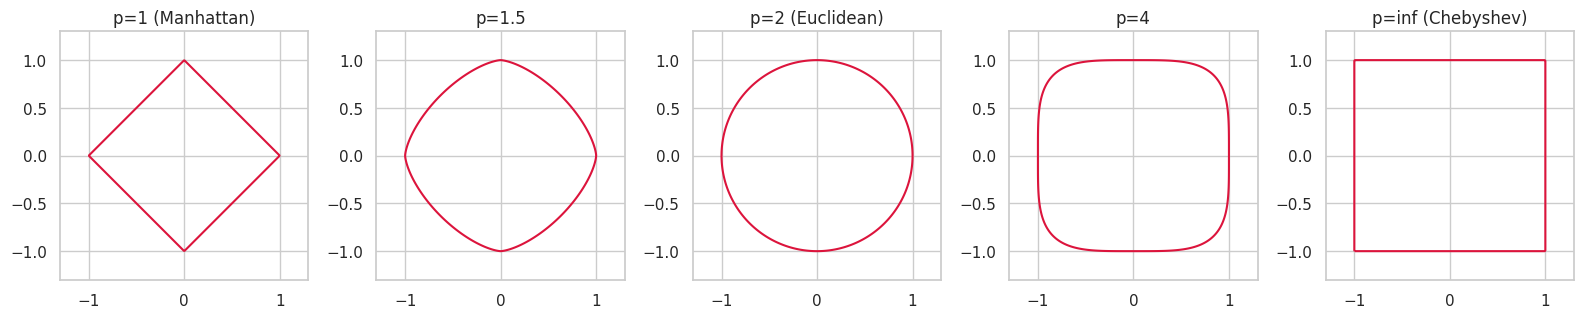

In [4]:
xx, yy = np.meshgrid(np.linspace(-1.3, 1.3, 400), np.linspace(-1.3, 1.3, 400))
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, p in zip(axes, [1, 1.5, 2, 4, np.inf]):
    norm = np.maximum(np.abs(xx), np.abs(yy)) if np.isinf(p) else (np.abs(xx) ** p + np.abs(yy) ** p) ** (1 / p)
    ax.contour(xx, yy, norm, levels=[1.0], colors="crimson")
    ax.set_aspect("equal"); ax.set_title({1: "p=1 (Manhattan)", 2: "p=2 (Euclidean)", np.inf: "p=inf (Chebyshev)"}.get(p, f"p={p}"))
plt.tight_layout(); plt.show()

### 1.4 Distances depend on feature scale

A distance adds up differences *in the units of each feature*. Consider two people described by `age` (years) and `income` (dollars):

| | age | income |
|:--|:--:|:--:|
| Alice | 25 | 50 000 |
| Bob | 55 | 50 500 |
| Carol | 26 | 50 700 |

Alice and Bob differ by 30 years but only \$500; Alice and Carol differ by only one year but \$700. Who is closer to Alice?

In [5]:
people = pd.DataFrame({"age": [25, 55, 26], "income": [50000, 50500, 50700]}, index=["Alice", "Bob", "Carol"])
d_raw = pairwise_distances(people)
scaled = StandardScaler().fit_transform(people)
d_scaled = pairwise_distances(scaled)

print("Raw distances from Alice -> Bob: %.1f | Carol: %.1f   (Bob looks closer: income dominates)" % (d_raw[0, 1], d_raw[0, 2]))
print("Scaled distances from Alice -> Bob: %.2f | Carol: %.2f   (age now matters too: Carol is closer)" % (d_scaled[0, 1], d_scaled[0, 2]))

Raw distances from Alice -> Bob: 500.9 | Carol: 700.0   (Bob looks closer: income dominates)
Scaled distances from Alice -> Bob: 2.74 | Carol: 2.38   (age now matters too: Carol is closer)


Without scaling, the income column swamps age: Bob (30 years older) appears "closer" to Alice than Carol (a year older), because the raw distance is essentially just the income difference. After standardisation both features contribute comparably and the ranking flips: Carol becomes the nearer neighbour. This is why **feature scaling (Chapter 2) is essential before any distance-based model.**

### 1.5 Which metric should I choose?

The book gives a decision flowchart (Figure 4.1). In table form:

| Situation | Suggested metric |
|:----------|:-----------------|
| Continuous features, similar scale, no special structure | Euclidean (default) |
| Outliers or many irrelevant coordinates; grid-like data; high dimension | Manhattan (less sensitive to a single large difference) |
| Tune the shape of the distance | Minkowski with $p$ as a hyperparameter |
| Only the largest coordinate difference matters | Chebyshev |
| Direction matters more than magnitude (text, TF-IDF vectors, embeddings) | Cosine |
| Binary or categorical features | Hamming (or Jaccard for sparse binary sets) |

## 2. Understanding KNN

**K-nearest neighbours** is a supervised algorithm for both **classification** and **regression**. The idea is very simple: to predict the label of a new point, find the $k$ training points closest to it (using a distance metric) and let them "vote".

- **Classification:** predict the *majority class* among the $k$ neighbours.
- **Regression:** predict the *mean* (optionally weighted) of the neighbours' target values.

KNN is a **lazy learner** (or instance-based): `fit()` essentially just stores the training data, and all work happens at prediction time. It makes no assumptions about the form of the decision boundary, so it can model very irregular shapes, at the cost of memory and prediction speed.

### 2.1 Getting ready: the Iris dataset

The Iris dataset has 150 flowers of 3 species, described by 4 measurements. We split it 80/20 with the book's seed (`random_state=2024`).

In [6]:
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2024)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Class counts in train:", np.bincount(y_train), "| in test:", np.bincount(y_test))

Train: (120, 4) | Test: (30, 4)
Class counts in train: [38 42 40] | in test: [12  8 10]


### 2.2 Basic KNN with scikit-learn (the book's recipe)

In [7]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9333333333333333


With default settings and $k=3$, the model reaches about 93% accuracy on the 30 test flowers (the book reports 0.9333), which is a good start. Note that with such a small test set, one extra mistake changes the accuracy by 3.3 percentage points, so we will treat these single-split numbers with caution.

### 2.3 KNN from scratch

To demystify the algorithm, we implement it in a dozen lines of NumPy: compute all distances, take the $k$ smallest, and vote. Then we check that it matches scikit-learn.

In [8]:
def knn_predict(X_train, y_train, X_query, k=3):
    # distance of every query point to every training point -> (n_query, n_train)
    d = np.linalg.norm(X_query[:, None, :] - X_train[None, :, :], axis=2)
    nearest = np.argsort(d, axis=1)[:, :k]               # indices of the k closest training points
    votes = y_train[nearest]                              # their labels
    return np.array([np.bincount(row).argmax() for row in votes])   # majority vote

y_scratch = knn_predict(X_train, y_train, X_test, k=3)
print("From-scratch accuracy:", accuracy_score(y_test, y_scratch))
print("Identical to scikit-learn predictions:", np.array_equal(y_scratch, y_pred))

# Inspect the neighbours of the first test flower
d0 = np.linalg.norm(X_train - X_test[0], axis=1)
idx = np.argsort(d0)[:3]
print("\nTest flower 0 features:", X_test[0], "-> true class", y_test[0])
print("Its 3 nearest neighbours (train indices):", idx, "with classes", y_train[idx], "and distances", np.round(d0[idx], 3))
dist_sk, idx_sk = knn.kneighbors(X_test[:1])
print("scikit-learn kneighbors() agrees:", np.array_equal(idx_sk[0], idx))

From-scratch accuracy: 0.9333333333333333
Identical to scikit-learn predictions: True

Test flower 0 features: [5.8 4.  1.2 0.2] -> true class 0
Its 3 nearest neighbours (train indices): [48  0 77] with classes [0 0 0] and distances [0.412 0.469 0.557]
scikit-learn kneighbors() agrees: True


The home-made version is identical to the library's, which confirms how simple the principle is. The method `kneighbors()` exposes the neighbours themselves, which is very useful for *explaining* a prediction ("this flower was classified as versicolor because its three closest known flowers are versicolor").

### 2.4 KNN for regression

For a numeric target KNN averages the neighbours' values. The prediction is a **piecewise-constant** function whose smoothness is controlled by $k$:

$$\hat{y}(\mathbf{x})=\frac{1}{k}\sum_{i\in\mathcal{N}_k(\mathbf{x})}y_i$$

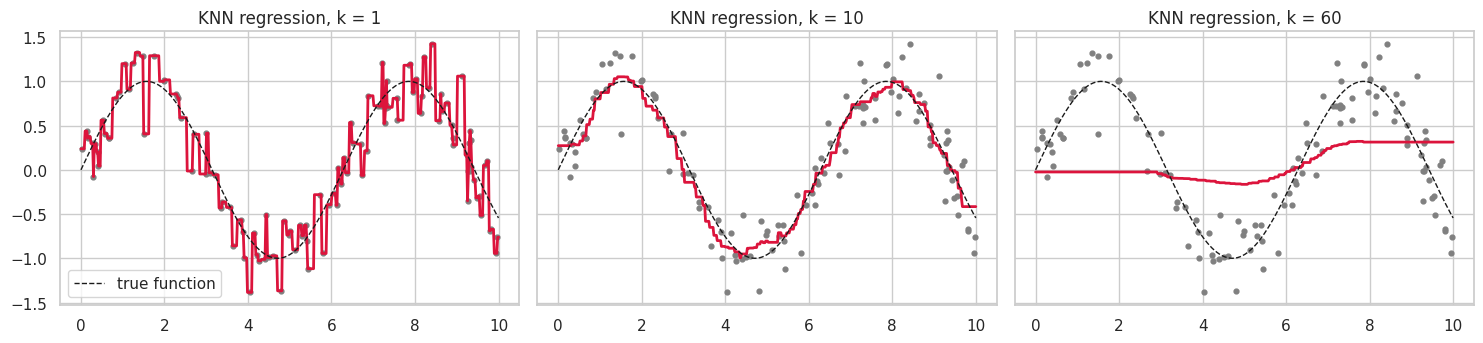

In [9]:
rng = np.random.default_rng(0)
x_reg = np.sort(rng.uniform(0, 10, 120))
y_reg = np.sin(x_reg) + rng.normal(0, 0.25, x_reg.size)
grid = np.linspace(0, 10, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, k in zip(axes, [1, 10, 60]):
    reg = KNeighborsRegressor(n_neighbors=k).fit(x_reg.reshape(-1, 1), y_reg)
    ax.scatter(x_reg, y_reg, s=12, color="gray"); ax.plot(grid, reg.predict(grid), color="crimson", lw=2)
    ax.plot(grid, np.sin(grid), "k--", lw=1, label="true function"); ax.set_title(f"KNN regression, k = {k}")
axes[0].legend(); plt.tight_layout(); plt.show()

This picture is the best intuition for the role of $k$:

- **$k=1$** follows every noisy point exactly (low bias, **high variance**: overfitting).
- **$k=10$** gives a smooth curve close to the true function.
- **$k=60$** averages over half of the data and flattens the curve (high bias: **underfitting**).

### 2.5 How it works: the three ingredients

1. **Choosing $k$.** A small $k$ is sensitive to noise; a large $k$ smooths predictions but may overlook local patterns.
2. **Distance calculation.** Euclidean, Manhattan, or another Minkowski-type metric (Section 1). The metric can substantially change the outcome.
3. **Voting mechanism.** Majority vote for classification, average for regression; with `weights="distance"` closer neighbours get a larger vote (weight $1/d$).

### 2.6 Choosing $k$: train/test curve and cross-validation

Common strategies for picking $k$ are cross-validation, and the *elbow method*: plot the score against $k$ and look for the point after which gains diminish. We use the Wine dataset here because Iris is too easy to show the effect, and we scale inside a pipeline.

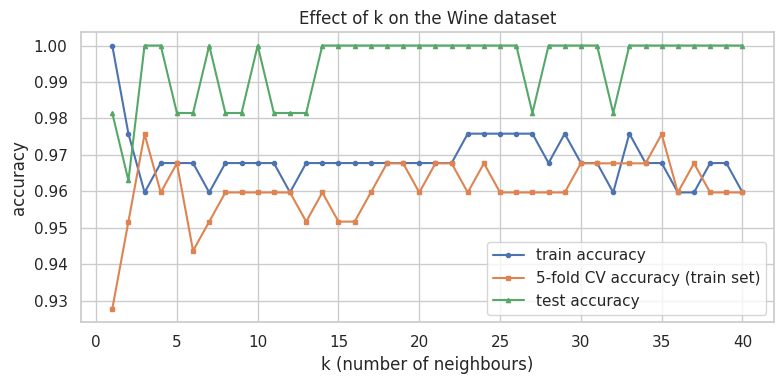

k = 1 -> train accuracy 1.000 (memorises the training set) but CV accuracy 0.928
Best k by cross-validation: 3 (CV accuracy 0.976)


In [10]:
wine = load_wine()
Xw, yw = wine.data, wine.target
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.3, random_state=2024, stratify=yw)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)

ks = list(range(1, 41))
train_acc, test_acc, cv_acc = [], [], []
for k in ks:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(Xw_tr, yw_tr)
    train_acc.append(pipe.score(Xw_tr, yw_tr)); test_acc.append(pipe.score(Xw_te, yw_te))
    cv_acc.append(cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), Xw_tr, yw_tr, cv=cv5).mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, train_acc, "o-", ms=3, label="train accuracy"); ax.plot(ks, cv_acc, "s-", ms=3, label="5-fold CV accuracy (train set)"); ax.plot(ks, test_acc, "^-", ms=3, label="test accuracy")
ax.set_xlabel("k (number of neighbours)"); ax.set_ylabel("accuracy"); ax.legend(); ax.set_title("Effect of k on the Wine dataset")
plt.tight_layout(); plt.show()

best_k = ks[int(np.argmax(cv_acc))]
print(f"k = 1 -> train accuracy {train_acc[0]:.3f} (memorises the training set) but CV accuracy {cv_acc[0]:.3f}")
print(f"Best k by cross-validation: {best_k} (CV accuracy {max(cv_acc):.3f})")

Three things to notice:

- With $k=1$ the **training accuracy is 100%** (each point is its own nearest neighbour), a typical sign of overfitting.
- The training accuracy decreases as $k$ increases, whereas the cross-validation accuracy is best for small-to-moderate $k$ and tends to decline when $k$ becomes too large (see the plot).
- Choose $k$ using **cross-validation on the training data**, not the test set. The test curve is shown only for illustration.

Using an odd $k$ in two-class problems avoids ties.

### 2.7 Decision boundaries

For two features we can visualise the regions where the classifier predicts each class. We use the two petal measurements of Iris (standardised) for $k=1$, $5$ and $30$.

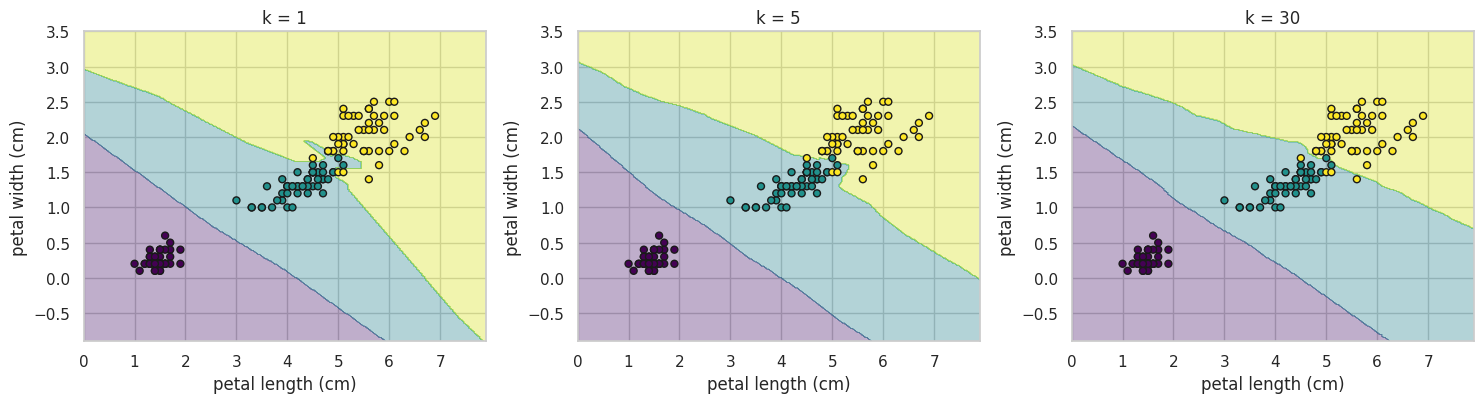

In [11]:
from sklearn.inspection import DecisionBoundaryDisplay

X2 = iris.data[:, 2:4]                       # petal length, petal width
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, k in zip(axes, [1, 5, 30]):
    clf = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X2, y)
    DecisionBoundaryDisplay.from_estimator(clf, X2, response_method="predict", ax=ax, alpha=0.35, cmap="viridis", grid_resolution=300)
    ax.scatter(X2[:, 0], X2[:, 1], c=y, cmap="viridis", edgecolor="k", s=25)
    ax.set_title(f"k = {k}"); ax.set_xlabel("petal length (cm)"); ax.set_ylabel("petal width (cm)")
plt.tight_layout(); plt.show()

With $k=1$ the boundary is jagged and wraps around individual points (it can create small "islands" around outliers). With larger $k$ the boundary becomes smoother and simpler. The right level of smoothness is the bias-variance trade-off again.

### 2.8 Neighbour search algorithms: `brute`, `kd_tree`, `ball_tree`

Predicting requires finding the nearest training points. Naive ("brute-force") search compares the query to *every* training point. `KDTree` and `BallTree` organise the data in a tree to skip most comparisons. The `algorithm` parameter selects the method (`"auto"` chooses for you). All three return the **same neighbours**, only the speed differs. KD-trees work well in low dimension (roughly below 15-20 features); in high dimensions all methods approach brute-force cost.

In [12]:
rng = np.random.default_rng(1)
X_big = rng.normal(size=(30000, 6)); y_big = (X_big[:, 0] + X_big[:, 1] ** 2 > 1).astype(int)
Q = rng.normal(size=(3000, 6))

preds, rows = {}, []
for algo in ["brute", "kd_tree", "ball_tree"]:
    model = KNeighborsClassifier(n_neighbors=5, algorithm=algo)
    t0 = time.time(); model.fit(X_big, y_big); t_fit = time.time() - t0
    t0 = time.time(); preds[algo] = model.predict(Q); t_pred = time.time() - t0
    rows.append({"algorithm": algo, "fit (s)": t_fit, "predict 3000 points (s)": t_pred})

print(pd.DataFrame(rows).set_index("algorithm"))
print("\nAll algorithms give identical predictions:", np.array_equal(preds["brute"], preds["kd_tree"]) and np.array_equal(preds["brute"], preds["ball_tree"]))

           fit (s)  predict 3000 points (s)
algorithm                                  
brute       0.0017                   0.2679
kd_tree     0.0257                   0.0715
ball_tree   0.0182                   0.4464

All algorithms give identical predictions: True


All three return exactly the same answers, but the speed differs. The KD-tree spends more time in `fit()` (building the tree) and then predicts several times faster than brute force on this low-dimensional dataset. The ball tree, however, was *not* faster here: it is designed for higher dimensions and non-Euclidean metrics, so it has no advantage on 6 well-behaved features. Which algorithm is fastest depends on the data, so benchmark if speed matters (`algorithm="auto"` makes a reasonable choice). For a lazy learner, **prediction speed** is the main practical limitation of KNN on large datasets.

### 2.9 Hands-on checklist for KNN
1. Choose `KNeighborsClassifier` (or `KNeighborsRegressor`).
2. Try several $k$ and observe the effect on performance.
3. Evaluate with accuracy or a confusion matrix on unseen data.
4. Experiment with different distance metrics and weighting.
5. Plot decision boundaries and highlight misclassified points.

## 3. Distance Metrics Overview: Comparing Metrics on Different Data

The metric defines what "near" means, so it can affect classification and clustering outcomes. This recipe compares metrics on two synthetic datasets with different geometry.

### 3.1 Getting ready: two datasets

1. **Noisy circles**: two concentric rings with a lot of noise (`make_circles`, `noise=0.3, factor=0.3`). The classes are separated by *radius*.
2. **Checkerboard**: points on a regular grid whose class alternates like the squares of a chessboard. Here the geometry is axis-aligned and grid-like, which hints at Manhattan-style distances.

Circles: (300, 2) | class balance: [150 150]
Checkerboard: (289, 2) | class balance: [145 144]


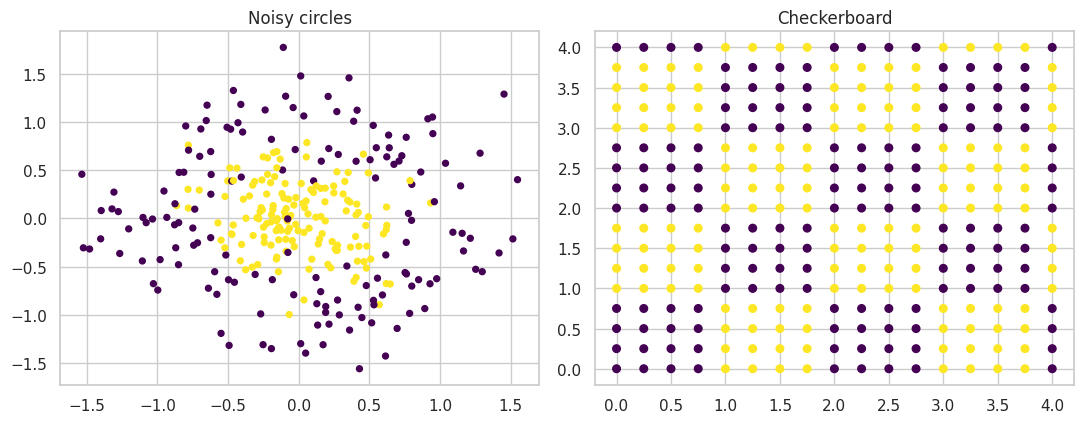

In [13]:
n_samples = 300
X_circles, y_circles = make_circles(n_samples=n_samples, noise=0.3, factor=0.3, random_state=2024)

x = np.linspace(0, 4, int(np.sqrt(n_samples)))
xx, yy = np.meshgrid(x, x)
X_board = np.column_stack((xx.ravel(), yy.ravel()))
y_board = np.mod(np.floor(xx.ravel()) + np.floor(yy.ravel()), 2).astype(int)

print("Circles:", X_circles.shape, "| class balance:", np.bincount(y_circles))
print("Checkerboard:", X_board.shape, "| class balance:", np.bincount(y_board))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].scatter(X_circles[:, 0], X_circles[:, 1], c=y_circles, cmap="viridis", s=18); axes[0].set_title("Noisy circles")
axes[1].scatter(X_board[:, 0], X_board[:, 1], c=y_board, cmap="viridis", s=30); axes[1].set_title("Checkerboard")
plt.tight_layout(); plt.show()

### 3.2 The book's experiment: one split

We split each dataset 80/20 (seed 2024), then train KNN ($k=3$) with `euclidean`, `manhattan` and `minkowski` metrics and record test accuracy.

In [14]:
metrics = ["euclidean", "manhattan", "minkowski"]
results = {"circles": {}, "checkerboard": {}}
for name, (Xd, yd) in {"circles": (X_circles, y_circles), "checkerboard": (X_board, y_board)}.items():
    Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, random_state=2024)
    for metric in metrics:
        knn_m = KNeighborsClassifier(n_neighbors=3, metric=metric).fit(Xtr, ytr)
        results[name][metric] = accuracy_score(yte, knn_m.predict(Xte))
print("Accuracy on ONE random split (the book's setting):")
pd.DataFrame(results).T

Accuracy on ONE random split (the book's setting):


,euclidean,manhattan,minkowski
circles,0.7833,0.7667,0.7833
checkerboard,0.8103,0.8448,0.8103


Two observations. First, `minkowski` and `euclidean` give **identical** accuracy, because scikit-learn's Minkowski defaults to $p=2$, which *is* the Euclidean distance. Second, the differences between the metrics are small and come from a test set of only 60 points, where a single sample changes the accuracy by 1.7 points. (In the book's run, Manhattan came out best on the circles and the authors suspect it may be "simply by luck"; with the data generated here the single-split ordering is different, which already shows how unstable such a ranking is.) We can test this properly: repeat the evaluation over **many random splits** and compare means and spreads.

### 3.3 A more careful comparison: repeated random splits

We also add `chebyshev`, `cosine` and a Minkowski with $p=3$. We use 200 random 80/20 splits per dataset.

In [15]:
from sklearn.model_selection import ShuffleSplit

metric_specs = {
    "euclidean (p=2)":  dict(metric="minkowski", p=2),
    "manhattan (p=1)":  dict(metric="minkowski", p=1),
    "minkowski p=3":    dict(metric="minkowski", p=3),
    "chebyshev":        dict(metric="chebyshev"),
    "cosine":           dict(metric="cosine"),
}
ss = ShuffleSplit(n_splits=200, test_size=0.2, random_state=0)

summary = {}
for ds_name, (Xd, yd) in {"circles": (X_circles, y_circles), "checkerboard": (X_board, y_board)}.items():
    for m_name, kwargs in metric_specs.items():
        scores = cross_val_score(KNeighborsClassifier(n_neighbors=3, algorithm="brute", **kwargs), Xd, yd, cv=ss)
        summary[(ds_name, m_name)] = (scores.mean(), scores.std(), scores.std() / np.sqrt(len(scores)))

res = pd.DataFrame(summary, index=["mean accuracy", "std over splits", "std. error of mean"]).T
res.index.names = ["dataset", "metric"]
res

mean accuracy  std over splits  std. error of mean
dataset      metric                                                             
circles      euclidean (p=2)         0.8447           0.0397              0.0028
             manhattan (p=1)         0.8430           0.0424              0.0030
             minkowski p=3           0.8434           0.0408              0.0029
             chebyshev               0.8403           0.0405              0.0029
             cosine                  0.4264           0.0524              0.0037
checkerboard euclidean (p=2)         0.8201           0.0476              0.0034
             manhattan (p=1)         0.8280           0.0475              0.0034
             minkowski p=3           0.8203           0.0478              0.0034
             chebyshev               0.7063           0.0587              0.0042
             cosine                  0.5146           0.0536              0.0038

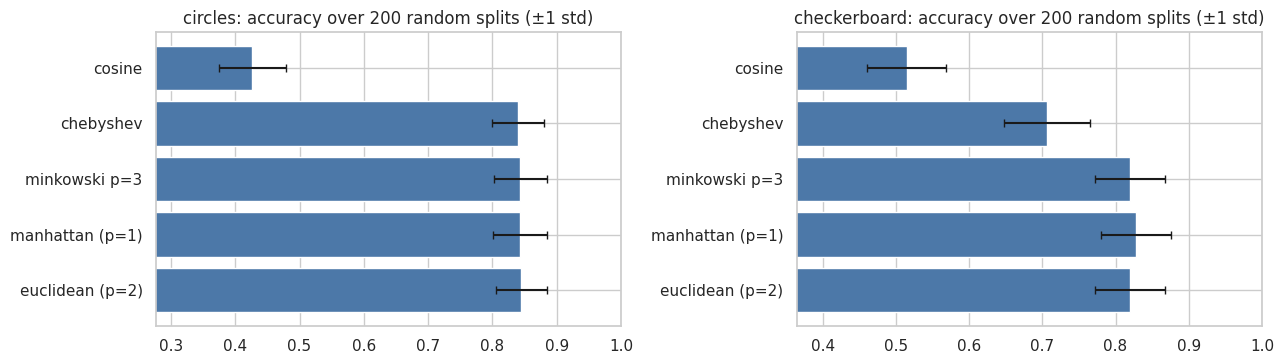

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for ax, ds in zip(axes, ["circles", "checkerboard"]):
    sub = res.loc[ds]
    ax.barh(sub.index, sub["mean accuracy"], xerr=sub["std over splits"], color="#4c78a8", capsize=3)
    ax.set_xlim(max(0, sub["mean accuracy"].min() - 0.15), 1.0); ax.set_title(f"{ds}: accuracy over 200 random splits (±1 std)")
plt.tight_layout(); plt.show()

Looking at the means *and* the spread across 200 splits gives a more reliable picture than one split:

- On the **noisy circles**, Euclidean, Manhattan, Minkowski ($p=3$) and Chebyshev are within about half a percentage point of each other, far less than the split-to-split standard deviation (about 4 points). Noise dominates, so there is no real winner, and a single-split "winner" is mostly luck, as the book suspected.
- **Cosine distance fails on both datasets** (accuracy around or below chance): it measures only the *angle* from the origin and ignores magnitude. On concentric circles, class membership is determined by the radius, and on the checkerboard by the position within the grid, so the angle carries almost no information.
- On the **checkerboard**, Manhattan is marginally the best (about 0.8 points above Euclidean; small compared with the spread over splits, so treat it as a mild tendency, not a certainty), consistent with the book's intuition for grid-like data. **Chebyshev is clearly worse** (about 0.71): it uses only the largest single-coordinate difference and ignores the other coordinate, which hurts when both coordinates determine the class.

**Lesson:** the "best" metric depends on the geometry of the problem; compare candidates with repeated or cross-validated evaluation, never with a single split.

### 3.4 Impact of the metric on model performance

| Aspect | Effect |
|:-------|:-------|
| **Sensitivity to scale** | Euclidean and Manhattan are driven by the largest-scale features, so standardise first |
| **Dimensionality** | In high dimensions distances concentrate (Chapter 3), and all metrics lose contrast; Manhattan tends to degrade more gracefully than Euclidean |
| **Outliers** | Euclidean squares the differences, so one huge coordinate dominates; Manhattan is more robust |
| **Data type** | Continuous: Minkowski family. Binary/categorical: Hamming/Jaccard. Text/embeddings: cosine |

### 3.5 Hamming distance for categorical data

When features are categorical or binary, the number of **mismatching positions** is the natural distance. Example with encoded customer profiles:

In [17]:
profiles = pd.DataFrame({"plan": ["basic", "pro", "basic", "pro"], "region": ["EU", "EU", "US", "US"], "mobile": ["yes", "yes", "no", "no"]},
                        index=["u1", "u2", "u3", "u4"])
codes = profiles.apply(lambda s: s.astype("category").cat.codes)
ham = pd.DataFrame(pairwise_distances(codes, metric="hamming"), index=profiles.index, columns=profiles.index)
print(profiles, "\n")
print("Hamming distance = fraction of attributes that differ:")
ham

     plan region mobile
u1  basic     EU    yes
u2    pro     EU    yes
u3  basic     US     no
u4    pro     US     no 

Hamming distance = fraction of attributes that differ:


,u1,u2,u3,u4
u1,0.0000,0.3333,0.6667,1.0000
u2,0.3333,0.0000,1.0000,0.6667
u3,0.6667,1.0000,0.0000,0.3333
u4,1.0000,0.6667,0.3333,0.0000


`u1` and `u2` differ only in `plan`, so the distance is 1/3; `u1` and `u4` differ in all three attributes, so the distance is 1. A KNN classifier with `metric="hamming"` would use exactly this notion of similarity.

### 3.6 Hands-on checklist for metrics
1. Create `KNeighborsClassifier` objects with different values of `metric` (`euclidean`, `manhattan`, `chebyshev`, `cosine`, ...).
2. Evaluate each with a **robust** protocol (cross-validation or repeated splits).
3. Compare accuracy and spread, and visualise the data to understand *why* a metric wins.

## 4. Hyperparameter Tuning in KNN

A **parameter** is learned by the model from data (the slope and intercept of a line, $y=mx+b$). A **hyperparameter** tells the model *how to learn*: it is set beforehand. For KNN the main hyperparameters are:

| Hyperparameter | Meaning |
|:---------------|:--------|
| `n_neighbors` ($k$) | Number of neighbours that vote |
| `weights` | `"uniform"` (all equal) or `"distance"` (closer neighbours count more) |
| `metric` / `p` | The distance function |
| `algorithm`, `leaf_size` | Search strategy (affects speed, not results) |

### 4.1 Grid search with cross-validation (the book's recipe)

`GridSearchCV` tries **every combination** in a grid, evaluating each by $k$-fold cross-validation, and returns the best. On Iris we tune `n_neighbors`, `weights` and `metric`.

In [18]:
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"],
}
grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring="accuracy")
grid_search.fit(X_train, y_train)

print("Combinations evaluated:", len(grid_search.cv_results_["params"]), "(5 x 2 x 2) x 5 folds =", 20 * 5, "fits")
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", round(grid_search.best_score_, 4))
print("Test accuracy of the refitted best model:", round(grid_search.score(X_test, y_test), 4))

Combinations evaluated: 20 (5 x 2 x 2) x 5 folds = 100 fits
Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.9917
Test accuracy of the refitted best model: 0.9333


The best cross-validation score is very high, but note a subtle point: several combinations usually achieve almost the same score. Let's look at the full results table and judge whether the "best" parameters are really better than their competitors.

In [19]:
res_gs = pd.DataFrame(grid_search.cv_results_)
cols = ["param_n_neighbors", "param_weights", "param_metric", "mean_test_score", "std_test_score", "rank_test_score"]
res_gs[cols].sort_values("rank_test_score").head(10).reset_index(drop=True)

,param_n_neighbors,param_weights,param_metric,mean_test_score,std_test_score,rank_test_score
0,9,uniform,euclidean,0.9917,0.0167,1
1,9,distance,euclidean,0.9917,0.0167,1
2,3,uniform,euclidean,0.9833,0.0204,3
3,3,distance,euclidean,0.9833,0.0204,3
4,5,distance,euclidean,0.9833,0.0204,3
5,5,uniform,euclidean,0.9833,0.0204,3
6,7,distance,euclidean,0.9833,0.0204,3
7,7,uniform,euclidean,0.9833,0.0204,3
8,11,uniform,euclidean,0.9833,0.0204,3
9,11,distance,euclidean,0.9833,0.0204,3


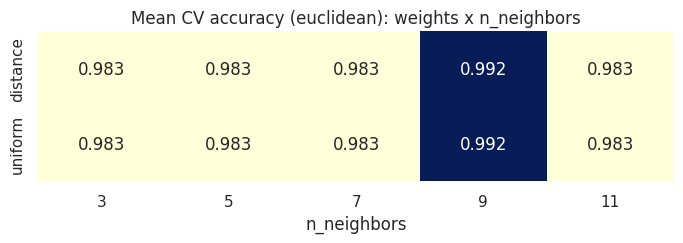

In [20]:
pivot = (res_gs[res_gs["param_metric"] == "euclidean"]
         .pivot(index="param_weights", columns="param_n_neighbors", values="mean_test_score").astype(float))
fig, ax = plt.subplots(figsize=(7, 2.6))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", cbar=False, ax=ax)
ax.set_title("Mean CV accuracy (euclidean): weights x n_neighbors"); ax.set_xlabel("n_neighbors"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Because the scores in the table are so close (differences smaller than the fold-to-fold standard deviation `std_test_score`), the exact "winner" among the top combinations is **not statistically meaningful**; the choice among them could change with another random split. When several settings tie, prefer the simpler or more robust one (for example a moderate $k$).

How it works:
- **Grid search** exhaustively searches the specified grid for the best combination.
- **Cross-validation** (here 5-fold) evaluates each combination on different subsets, giving a more reliable estimate than one split and reducing the risk of tuning to a lucky split.

After tuning, evaluate the final model **once** on the held-out test set.

### 4.2 Randomised search

When the grid is large, `RandomizedSearchCV` samples a fixed number of random combinations from distributions, which is cheaper and often just as good. We demonstrate on the Wine data with a pipeline that includes scaling (so that distances make sense), and we also tune the Minkowski power $p$.

In [21]:
from scipy.stats import randint, uniform

pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
param_dist = {
    "knn__n_neighbors": randint(1, 31),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 1.5, 2, 3],                    # Minkowski power (metric="minkowski" is the default)
}
t0 = time.time()
rs = RandomizedSearchCV(pipe, param_dist, n_iter=25, cv=cv5, scoring="accuracy", random_state=2024, n_jobs=-1).fit(Xw_tr, yw_tr)
print(f"RandomizedSearchCV: 25 random candidates in {time.time()-t0:.1f}s")
print("Best parameters:", rs.best_params_)
print(f"Best CV accuracy: {rs.best_score_:.4f} | test accuracy: {rs.score(Xw_te, yw_te):.4f}")

RandomizedSearchCV: 25 random candidates in 0.4s
Best parameters: {'knn__n_neighbors': 15, 'knn__p': 3, 'knn__weights': 'distance'}
Best CV accuracy: 0.9677 | test accuracy: 0.9815


### 4.3 Nested cross-validation: an honest estimate of a *tuned* model

There is a subtle trap: the `best_score_` from a grid search is **optimistically biased**, because we picked the maximum over many noisy estimates. To estimate how the *whole procedure* (tuning + fitting) will perform on new data, use **nested cross-validation**: an *inner* loop tunes the hyperparameters, an *outer* loop evaluates the tuned model on data the inner loop never saw.

In [22]:
inner_grid = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]),
    {"knn__n_neighbors": list(range(1, 22, 2)), "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]},
    cv=StratifiedKFold(3, shuffle=True, random_state=1), scoring="accuracy", n_jobs=-1)

outer = StratifiedKFold(5, shuffle=True, random_state=2)
nested = cross_val_score(inner_grid, Xw, yw, cv=outer, scoring="accuracy")
non_nested = inner_grid.fit(Xw, yw).best_score_

print("Outer-fold accuracies of the tuned model:", np.round(nested, 3))
print(f"Nested CV estimate (honest): {nested.mean():.4f} ± {nested.std():.4f}")
print(f"Non-nested best_score_ (optimistic): {non_nested:.4f}")

Outer-fold accuracies of the tuned model: [1.    1.    0.917 0.971 1.   ]
Nested CV estimate (honest): 0.9776 ± 0.0324
Non-nested best_score_ (optimistic): 0.9888


The nested estimate describes how the *procedure* will behave on unseen data; the non-nested `best_score_` is usually equal or somewhat higher. On this easy dataset they are close, but on small or noisy datasets the gap can be large, so nested CV is the right tool when you must *report* performance of a tuned model.

### 4.4 Hands-on checklist for tuning
1. Build a `Pipeline` with scaling and `KNeighborsClassifier`.
2. Define a grid (or distributions) over `n_neighbors`, `weights`, `p`/`metric`.
3. Run `GridSearchCV` or `RandomizedSearchCV` on the training data.
4. Inspect `best_params_`, `best_score_` and the whole `cv_results_` table.
5. Evaluate the refitted best model once on the test set.

## 5. Evaluating KNN Performance

Evaluation tells us how well the model predicts and where it fails. This recipe covers cross-validation scores, learning curves, the confusion matrix, and the classification report. We use the best model found by the grid search on Iris.

### 5.1 Cross-validation scores

In [23]:
best_knn = grid_search.best_estimator_
cv_scores = cross_val_score(best_knn, X_train, y_train, cv=5)
print("Cross-validation scores:", np.round(cv_scores, 4))
print("Mean CV score:", round(cv_scores.mean(), 4))
print("Standard deviation:", round(cv_scores.std(), 4))

Cross-validation scores: [0.9583 1.     1.     1.     1.    ]
Mean CV score: 0.9917
Standard deviation: 0.0167


A low standard deviation means the model's performance is **stable** across different subsets of the data.

### 5.2 Learning curves

A **learning curve** plots training and validation score against the *size of the training set*. It diagnoses whether the model suffers from high bias (both curves low and converged: more data will not help) or high variance (a large gap between the curves: more data or a simpler model may help).

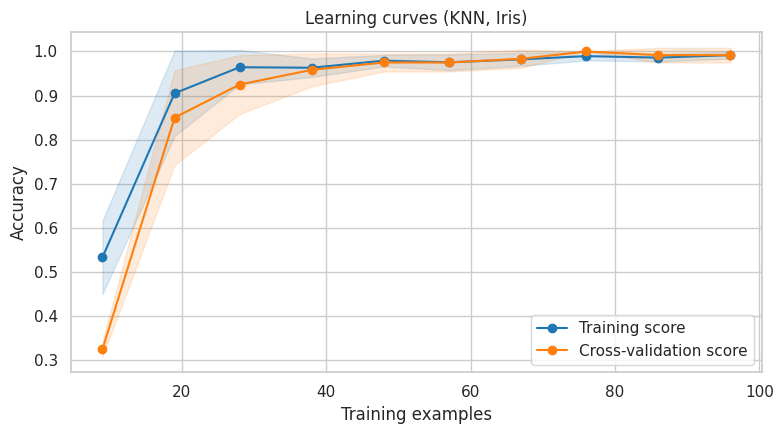

Final gap between training and validation score: 0.0


In [24]:
train_sizes, train_scores, val_scores = learning_curve(
    best_knn, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 10), cv=5, shuffle=True, random_state=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
for scores, label, color in [(train_scores, "Training score", "#1f77b4"), (val_scores, "Cross-validation score", "#ff7f0e")]:
    m, s = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(train_sizes, m, "o-", label=label, color=color); ax.fill_between(train_sizes, m - s, m + s, alpha=0.15, color=color)
ax.set_xlabel("Training examples"); ax.set_ylabel("Accuracy"); ax.set_title("Learning curves (KNN, Iris)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print("Final gap between training and validation score:", round(train_scores.mean(axis=1)[-1] - val_scores.mean(axis=1)[-1], 4))

Both curves are high and close together at the full training size (the final gap printed above is about zero), and the validation curve flattens out: the model is neither badly over- nor under-fitting, and additional data would give limited gains.

### 5.3 Confusion matrix

The **confusion matrix** counts, for each true class (rows), how many samples were predicted as each class (columns). The diagonal holds the correct predictions. For one class treated as "positive":

| | Predicted positive | Predicted negative |
|:--|:--:|:--:|
| **Actually positive** | True Positive (TP) | False Negative (FN) |
| **Actually negative** | False Positive (FP) | True Negative (TN) |

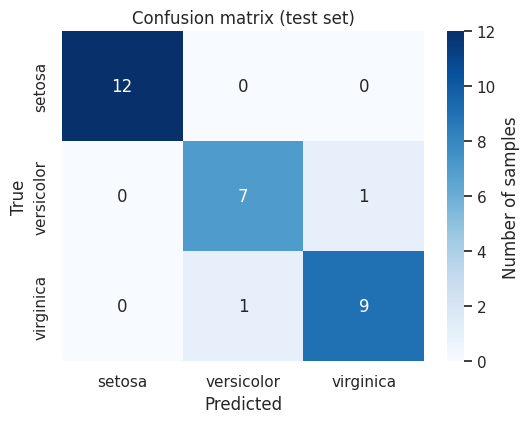

Correct predictions (diagonal): 28 of 30


In [25]:
y_pred_best = best_knn.predict(X_test)
class_names = iris.target_names
cm = confusion_matrix(y_test, y_pred_best)

fig, ax = plt.subplots(figsize=(5.5, 4.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, cbar_kws={"label": "Number of samples"}, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test set)")
plt.tight_layout(); plt.show()
print("Correct predictions (diagonal):", np.trace(cm), "of", cm.sum())

### 5.4 Classification report and the metrics behind it

The classification report summarises per-class **precision**, **recall** and **F1-score**:

$$\text{Precision}=\frac{TP}{TP+FP},\qquad \text{Recall}=\frac{TP}{TP+FN},\qquad F_1=2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}$$

- **Precision**: of the samples predicted as class $c$, how many truly are $c$? (How trustworthy is a positive prediction?)
- **Recall (sensitivity)**: of the samples that truly are $c$, how many did we find? (How complete are we?)
- **$F_1$**: the harmonic mean of both, which is high only when both are high.
- **Macro average**: unweighted mean over classes. **Weighted average**: mean weighted by class frequency (support).

In [26]:
report_dict = classification_report(y_test, y_pred_best, target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).T
report_df.style.background_gradient(cmap="Blues", subset=["precision", "recall", "f1-score"]).format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:.0f}"})

,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12
versicolor,0.875,0.875,0.875,8
virginica,0.900,0.900,0.900,10
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.925,0.925,30
weighted avg,0.933,0.933,0.933,30


Let's make sure we understand the numbers by recomputing one class by hand from the confusion matrix, treating "versicolor" as the positive class.

In [27]:
c = 1                                   # index of "versicolor"
TP = cm[c, c]
FP = cm[:, c].sum() - TP                # predicted c but actually something else
FN = cm[c, :].sum() - TP                # actually c but predicted something else
precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / (TP + FN) if TP + FN else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

print(f"Versicolor: TP={TP}, FP={FP}, FN={FN}")
print(f"By hand       -> precision={precision:.3f}, recall={recall:.3f}, F1={f1:.3f}")
print(f"classification_report -> precision={report_dict['versicolor']['precision']:.3f}, recall={report_dict['versicolor']['recall']:.3f}, F1={report_dict['versicolor']['f1-score']:.3f}")

Versicolor: TP=7, FP=1, FN=1
By hand       -> precision=0.875, recall=0.875, F1=0.875
classification_report -> precision=0.875, recall=0.875, F1=0.875


The hand calculation matches the report. Note: a perfect score such as 100% for *setosa* should normally raise suspicion, but the Iris dataset is known to be easy (setosa is linearly separable from the other two species). More generally, a "very good" score only has meaning relative to the **business problem**: 95% accuracy may be excellent for one task and unacceptable for another.

### 5.5 Probabilistic evaluation: ROC-AUC

KNN can output class probabilities (the fraction of neighbours voting for each class) through `predict_proba`. The **ROC-AUC** score summarises how well the model *ranks* positives above negatives across all thresholds. For multiple classes we use the one-vs-rest average.

In [28]:
proba = best_knn.predict_proba(X_test)
print("Probabilities for the first 3 test flowers (fraction of weighted neighbour votes):")
print(pd.DataFrame(proba[:3], columns=class_names).round(3))
print("\nMulticlass ROC-AUC (one-vs-rest):", round(roc_auc_score(y_test, proba, multi_class="ovr"), 4))

Probabilities for the first 3 test flowers (fraction of weighted neighbour votes):
   setosa  versicolor  virginica
0  1.0000      0.0000     0.0000
1  1.0000      0.0000     0.0000
2  0.0000      1.0000     0.0000

Multiclass ROC-AUC (one-vs-rest): 0.9597


### 5.6 Imbalanced data: why accuracy alone can lie

When one class vastly outnumbers another, a model that always predicts the majority class achieves a high accuracy while being useless. We build a dataset with a 5% minority class (think fraud) and compare metrics.

In [29]:
from sklearn.dummy import DummyClassifier

X_imb, y_imb = make_classification(n_samples=6000, n_features=10, n_informative=5, n_redundant=0, weights=[0.95, 0.05],
                                   flip_y=0.01, class_sep=1.0, random_state=0)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(X_imb, y_imb, test_size=0.25, stratify=y_imb, random_state=0)
print("Class counts (train):", np.bincount(yi_tr), "-> minority share = %.1f%%" % (100 * yi_tr.mean()))

def imbalance_metrics(model, Xte, yte):
    pred = model.predict(Xte); proba = model.predict_proba(Xte)[:, 1]
    return {"accuracy": accuracy_score(yte, pred), "balanced accuracy": balanced_accuracy_score(yte, pred),
            "precision (minority)": precision_score(yte, pred, zero_division=0), "recall (minority)": recall_score(yte, pred),
            "F1 (minority)": f1_score(yte, pred), "ROC-AUC": roc_auc_score(yte, proba), "PR-AUC": average_precision_score(yte, proba)}

dummy = DummyClassifier(strategy="most_frequent").fit(Xi_tr, yi_tr)
knn_imb = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xi_tr, yi_tr)
imb_table = pd.DataFrame({"Always predict majority": imbalance_metrics(dummy, Xi_te, yi_te), "KNN (k=5)": imbalance_metrics(knn_imb, Xi_te, yi_te)}).T
imb_table

Class counts (train): [4256  244] -> minority share = 5.4%


,accuracy,balanced accuracy,precision (minority),recall (minority),F1 (minority),ROC-AUC,PR-AUC
Always predict majority,0.9460,0.5000,0.0000,0.0000,0.0000,0.5000,0.0540
KNN (k=5),0.9567,0.6162,0.8636,0.2346,0.3689,0.7948,0.4184


The "always predict the majority class" baseline reaches an accuracy of about 95% while finding **none** of the minority cases (recall 0, balanced accuracy 0.5). KNN has a similar accuracy but its **recall on the minority class is low**, which is the metric that really matters in an imbalanced problem. Hence:

- Use **precision, recall, F1** (for the minority class), **balanced accuracy**, and threshold-free metrics such as **ROC-AUC** or, even better for rare positives, **PR-AUC** (average precision).
- Rebalancing the training data can help. KNN has no `class_weight`, but we can **oversample** the minority class (only in the training set!) by resampling it with replacement:

In [30]:
rng = np.random.default_rng(0)
minority_idx = np.where(yi_tr == 1)[0]
majority_idx = np.where(yi_tr == 0)[0]
extra = rng.choice(minority_idx, size=len(majority_idx) - len(minority_idx), replace=True)     # replicate until balanced
bal_idx = np.concatenate([majority_idx, minority_idx, extra])

knn_bal = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xi_tr[bal_idx], yi_tr[bal_idx])
cmp = pd.DataFrame({"KNN (original data)": imbalance_metrics(knn_imb, Xi_te, yi_te), "KNN (minority oversampled)": imbalance_metrics(knn_bal, Xi_te, yi_te)}).T
cmp

,accuracy,balanced accuracy,precision (minority),recall (minority),F1 (minority),ROC-AUC,PR-AUC
KNN (original data),0.9567,0.6162,0.8636,0.2346,0.3689,0.7948,0.4184
KNN (minority oversampled),0.9233,0.7092,0.3455,0.4691,0.3979,0.7707,0.2690


Oversampling raises the **recall** of the minority class, typically at the cost of lower precision (more false alarms): this is the precision/recall trade-off, and the right balance depends on the cost of each error type. Note that plain duplication with $k$-NN can be misleading, because the duplicated points are their own nearest neighbours, so the evaluation must always be done on an untouched, *non-resampled* test set as above. Libraries such as `imbalanced-learn` offer more sophisticated resampling (for example SMOTE).

### 5.7 Hands-on checklist for evaluation
1. Split the data and fit the model on the training part.
2. Predict on the test set.
3. Build a confusion matrix and compute precision, recall and F1 per class.
4. Add threshold-free metrics (ROC-AUC / PR-AUC) when the class balance is skewed.
5. Plot the confusion matrix and learning curve for diagnosis.

## 6. Practical Exercises with KNN Models

The three exercises of the book, each on a *different dataset* so that all the concepts are linked together: preprocessing (Chapter 2), pipelines, tuning, and evaluation.

### Exercise 1: build a KNN classifier on a dataset that needs preprocessing

**Breast Cancer Wisconsin**: 569 tumours, 30 numeric features with very different scales, target = malignant (0) / benign (1). Steps: load → preprocess (scale) → train → predict → evaluate. We also run the same model *without* scaling to quantify why preprocessing was needed.

In [31]:
bc = load_breast_cancer()
Xb, yb = bc.data, bc.target
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=2024, stratify=yb)

print("Feature scale range (std of each feature): min = %.4f, max = %.1f" % (Xb.std(axis=0).min(), Xb.std(axis=0).max()))

raw_knn = KNeighborsClassifier(n_neighbors=5).fit(Xb_tr, yb_tr)
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xb_tr, yb_tr)

rows = []
for name, model in [("KNN, raw features", raw_knn), ("KNN, standardised", scaled_knn)]:
    pred = model.predict(Xb_te)
    rows.append({"model": name, "accuracy": accuracy_score(yb_te, pred), "precision": precision_score(yb_te, pred),
                 "recall": recall_score(yb_te, pred), "F1": f1_score(yb_te, pred)})
pd.DataFrame(rows).set_index("model")

Feature scale range (std of each feature): min = 0.0026, max = 568.9


,accuracy,precision,recall,F1
model,,,,
"KNN, raw features",0.9386,0.9577,0.9444,0.9510
"KNN, standardised",0.9474,0.9342,0.9861,0.9595


Scaling improves accuracy and especially recall (fewer malignant tumours are missed, at a small cost in precision). Features such as `area` (hundreds to thousands) dominate the raw distance, whereas smoothness-type features have values below 1. Standardisation lets all 30 features contribute. The gain on this single split is modest, so it should be confirmed with cross-validation, but it goes in the direction predicted by theory.

### Exercise 2: tuning hyperparameters with grid search on a different dataset

We use **Digits** (1797 images, 64 pixel features, 10 classes). We search over $k$, the weighting and the Minkowski power with a pipeline, using 5-fold CV.

In [32]:
digits = load_digits()
Xdg, ydg = digits.data, digits.target
Xdg_tr, Xdg_te, ydg_tr, ydg_te = train_test_split(Xdg, ydg, test_size=0.25, random_state=2024, stratify=ydg)

pipe_dg = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
grid_dg = {"knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15], "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]}
t0 = time.time()
gs_dg = GridSearchCV(pipe_dg, grid_dg, cv=5, scoring="accuracy", n_jobs=-1).fit(Xdg_tr, ydg_tr)
print(f"Grid search ({len(gs_dg.cv_results_['params'])} candidates x 5 folds) took {time.time()-t0:.1f}s")
print("Best parameters:", gs_dg.best_params_)
print(f"Best CV accuracy: {gs_dg.best_score_:.4f} | Test accuracy: {gs_dg.score(Xdg_te, ydg_te):.4f}")

# Does scaling help for digits too? (pixel values are all in 0..16, so scaling is not crucial)
no_scale = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [1, 3, 5, 7, 9], "weights": ["uniform", "distance"], "p": [1, 2]}, cv=5, n_jobs=-1).fit(Xdg_tr, ydg_tr)
print(f"For comparison, WITHOUT scaling: best CV accuracy = {no_scale.best_score_:.4f}")

Grid search (28 candidates x 5 folds) took 1.3s
Best parameters: {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV accuracy: 0.9777 | Test accuracy: 0.9733


For comparison, WITHOUT scaling: best CV accuracy = 0.9896


Digits are a good example of a case where all features already share the same units (pixel counts 0-16), so scaling is less crucial than for the breast-cancer data. (Standardising pixels can even slightly hurt, since it amplifies rarely-used border pixels. This is why we *test* the preprocessing choice instead of assuming it.)

### Exercise 3: evaluating the tuned KNN classifier

We examine the tuned model on the held-out test set with a confusion matrix and look for the most confused digit pairs.

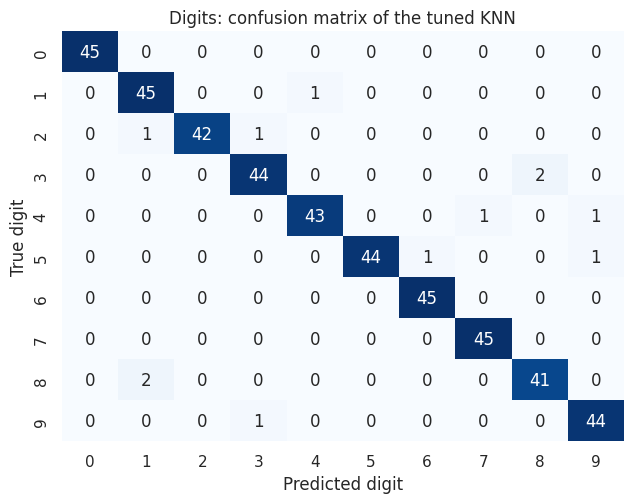

Test accuracy: 0.9733
Most frequent confusions (count, true -> predicted): [(2, '8->1'), (2, '3->8'), (1, '9->3'), (1, '5->9'), (1, '5->6')]

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        45
           1      0.938     0.978     0.957        46
           2      1.000     0.955     0.977        44
           3      0.957     0.957     0.957        46
           4      0.977     0.956     0.966        45
           5      1.000     0.957     0.978        46
           6      0.978     1.000     0.989        45
           7      0.978     1.000     0.989        45
           8      0.953     0.953     0.953        43
           9      0.957     0.978     0.967        45

    accuracy                          0.973       450
   macro avg      0.974     0.973     0.973       450
weighted avg      0.974     0.973     0.973       450



In [33]:
best_dg = gs_dg.best_estimator_
pred_dg = best_dg.predict(Xdg_te)
cm_dg = confusion_matrix(ydg_te, pred_dg)

fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(cm_dg, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_xlabel("Predicted digit"); ax.set_ylabel("True digit"); ax.set_title("Digits: confusion matrix of the tuned KNN")
plt.tight_layout(); plt.show()

off = cm_dg.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j] > 0], reverse=True)[:5]
print("Test accuracy:", round(accuracy_score(ydg_te, pred_dg), 4))
print("Most frequent confusions (count, true -> predicted):", [(int(c), f"{i}->{j}") for c, i, j in pairs])
print("\n" + classification_report(ydg_te, pred_dg, digits=3))

The tuned model makes only a dozen errors on 450 test images, scattered over several digit pairs (the printed list shows the most frequent ones, each occurring only once or twice), and the classification report shows high precision and recall for every class. Looking at such confusions is the best starting point for improving a model (more data for the confused classes, better features, a different metric).

### 6.1 Extensions: other neighbour-based tools

After mastering the basics you can explore further neighbour-based methods in scikit-learn.

**Radius neighbours.** Instead of the $k$ nearest points, use *all* training points within a fixed radius $r$. It adapts to local density (sparse regions have fewer voters). Points with no neighbour in the radius need an `outlier_label`.

In [34]:
scaler_i = StandardScaler().fit(X_train)
Xs_tr, Xs_te = scaler_i.transform(X_train), scaler_i.transform(X_test)
rows = []
for r in [0.5, 1.0, 1.5, 2.5]:
    rn = RadiusNeighborsClassifier(radius=r, weights="distance", outlier_label="most_frequent").fit(Xs_tr, y_train)
    rows.append({"radius": r, "test accuracy": rn.score(Xs_te, y_test)})
pd.DataFrame(rows).set_index("radius")

,test accuracy
radius,
0.5000,0.7667
1.0000,0.9667
1.5000,0.8667
2.5000,0.9000


The radius acts like an inverse of $k$: a very small radius leaves many points without neighbours (they fall back to the majority class, which explains the low accuracy at 0.5), while a larger radius averages more points. With only 30 test samples the differences between the larger radii are noisy, so the radius should be tuned by cross-validation just like $k$.

**Similarity search with `NearestNeighbors`.** The unsupervised `NearestNeighbors` class finds neighbours without any labels, which powers recommendation, retrieval and duplicate detection. Here: given one digit image, find the five most similar images in the dataset.

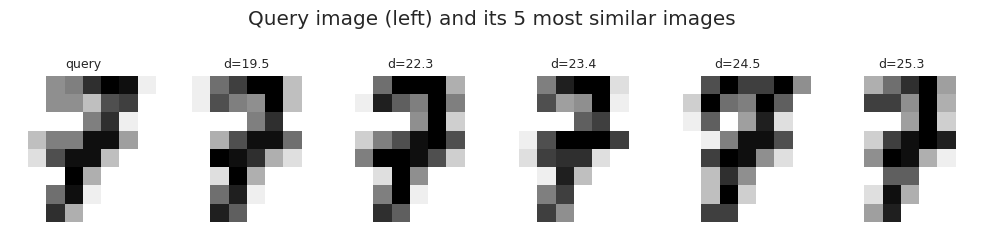

Labels of the retrieved images: [7 7 7 7 7 7]


In [35]:
nn = NearestNeighbors(n_neighbors=6, metric="euclidean").fit(Xdg)
query_id = 7
dist, ids = nn.kneighbors(Xdg[[query_id]])

fig, axes = plt.subplots(1, 6, figsize=(10, 2.2))
for ax, i, d in zip(axes, ids[0], dist[0]):
    ax.imshow(Xdg[i].reshape(8, 8), cmap="gray_r"); ax.axis("off")
    ax.set_title("query" if d == 0 else f"d={d:.1f}", fontsize=9)
plt.suptitle("Query image (left) and its 5 most similar images", y=1.05); plt.tight_layout(); plt.show()
print("Labels of the retrieved images:", ydg[ids[0]])

The retrieved images are visually similar to the query, and nearly always share its digit label, so even without any training labels, a nearest-neighbour search provides a meaningful similarity ranking.

Further topics you may explore: **DBSCAN, mean shift, spectral clustering** (distance/density-based clustering, Chapter 10), kernel density estimation, `KNNImputer` (Chapter 2), and approximate nearest-neighbour libraries for very large datasets.

## Summary

- **Distance metrics** (Euclidean, Manhattan, Minkowski, Chebyshev, cosine, Hamming) define similarity. Minkowski generalises Euclidean ($p=2$) and Manhattan ($p=1$). Distances depend on feature scale, so **scale first**.
- **KNN** predicts from the labels (or values) of the $k$ closest training points. It is easy to explain (we built it from scratch in a few lines), non-parametric and lazy: training is trivial but prediction can be slow on big data.
- **$k$ controls the bias-variance trade-off**: small $k$ overfits (training accuracy of 100% at $k=1$), large $k$ underfits. Choose it by cross-validation, and consider `weights="distance"`.
- The **best metric depends on the geometry** of the data. Single-split differences are often luck; repeated evaluation is needed to separate real effects from noise.
- **Tuning** with `GridSearchCV`/`RandomizedSearchCV` is easy, but the best score is optimistic; nested cross-validation gives an honest estimate. Ties among top candidates are common.
- **Evaluation** goes beyond accuracy: confusion matrix, precision, recall, F1, ROC-AUC; for **imbalanced data** use balanced accuracy, PR-AUC, and consider rebalancing the training data.

In **Chapter 5** we study **linear models and regularization**, starting with linear regression and its regularized variants.